In [76]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

In [78]:
from sklearn.preprocessing import RobustScaler

In [79]:
df = pd.read_csv('modified_data/cleaned_used_cars.csv')

In [80]:
df.head(10)

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,PostedYear,MonthNum
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,195000.0,2024,11
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,375000.0,2024,7
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,184999.0,2024,11
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,565000.0,2024,11
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,685000.0,2024,11
5,BMW,X3,2014,10,83000.0,Automatic,first,Diesel,1350000.0,2024,11
6,Toyota,Innova,2014,10,168000.0,Manual,second,Diesel,1025000.0,2024,11
7,BMW,5 Series,2019,5,25000.0,Automatic,second,Diesel,5950000.0,2024,11
8,Maruti Suzuki,maruti-suzuki-dzire,2020,4,33759.0,Manual,second,Petrol,622000.0,2024,11
9,Ford,Ecosport,2017,7,69713.0,Manual,second,Petrol,649000.0,2024,11


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14905 entries, 0 to 14904
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         14905 non-null  str    
 1   model         14905 non-null  str    
 2   Year          14905 non-null  int64  
 3   Age           14905 non-null  int64  
 4   kmDriven      14905 non-null  float64
 5   Transmission  14905 non-null  str    
 6   Owner         14905 non-null  str    
 7   FuelType      14905 non-null  str    
 8   AskPrice      14905 non-null  float64
 9   PostedYear    14905 non-null  int64  
 10  MonthNum      14905 non-null  int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 1.3 MB


In [82]:
df.describe()

,Year,Age,kmDriven,AskPrice,PostedYear,MonthNum
count,14905.000000,14905.000000,14905.000000,1.490500e+04,14905.000000,14905.000000
mean,2016.337404,7.662596,71078.347601,1.000914e+06,2023.999799,10.943308
std,4.331012,4.331012,57458.286188,1.590289e+06,0.014186,0.567333
min,1900.000000,0.000000,0.000000,1.500000e+04,2023.000000,1.000000
25%,2014.000000,5.000000,44000.000000,3.500000e+05,2024.000000,11.000000
50%,2017.000000,7.000000,65200.000000,5.750000e+05,2024.000000,11.000000
75%,2019.000000,10.000000,86000.000000,1.035000e+06,2024.000000,11.000000
max,2024.000000,124.000000,980002.000000,4.250000e+07,2024.000000,12.000000


In [83]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=str).columns.to_list()
cat_cols , num_cols

(['Brand', 'model', 'Transmission', 'Owner', 'FuelType'],
 ['Year', 'Age', 'kmDriven', 'AskPrice', 'PostedYear', 'MonthNum'])

In [84]:
df_cat = df[cat_cols]
df_num = df[num_cols]

In [85]:
df_cat.nunique()

Brand            42
model           434
Transmission      2
Owner             2
FuelType          4
dtype: int64

In [86]:
df.groupby(['Brand', 'model']).agg({'AskPrice': ['mean', 'median', 'count']}).sort_values(by=('AskPrice', 'count'), ascending=False)

AskPrice                 
                                   mean     median count
Brand         model                                     
Maruti Suzuki Wagon-R      3.453982e+05   325000.0   610
Honda         City         5.366750e+05   525000.0   550
Maruti Suzuki Ertiga       8.216171e+05   820000.0   439
              Swift        4.735222e+05   493000.0   410
              Swift-Dzire  4.715357e+05   470000.0   378
...                                 ...        ...   ...
Audi          RS7          1.250000e+06  1250000.0     1
Volvo         S80          1.350000e+06  1350000.0     1
BMW           M2           8.400000e+06  8400000.0     1
Toyota        Estima       2.300000e+06  2300000.0     1
Tata          Xenon XT     5.100000e+05   510000.0     1

[435 rows x 3 columns]

In [87]:
unique_brand_models_df = df[["Brand", "model"]].drop_duplicates()
unique_brand_models_df['model'].value_counts() 

model
Rexton       2
City         1
Innova       1
VentoTest    1
Swift        1
            ..
Versa        1
T-ROC        1
X-Trail      1
Ventury      1
Yeti         1
Name: count, Length: 434, dtype: int64

In [88]:
df[df['model'] == 'Rexton'].groupby('Brand').agg({'model': ['count'], 'AskPrice': ['mean', 'median']}).sort_values(by=('model', 'count'), ascending=False)

model  AskPrice          
          count      mean    median
Brand                              
Ssangyong     5  508000.6  490000.0
Mahindra      4  652250.0  674500.0

<Axes: xlabel='AskPrice_count', ylabel='AskPrice_mean'>

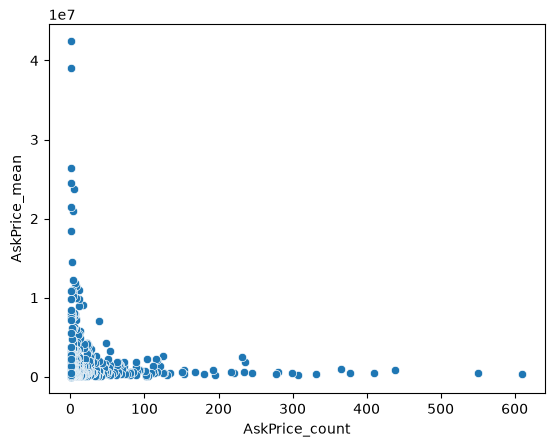

In [91]:
df_agg_on_brand_model_pairs = df.groupby(['Brand', 'model']).\
    agg({'AskPrice': ['mean', 'median', 'count']}).\
        sort_values(by=('AskPrice', 'count'), ascending=False)

df_agg_on_brand_model_pairs.columns = ['AskPrice_mean', 'AskPrice_median', 'AskPrice_count']
df_agg_on_brand_model_pairs.head(10)

sns.scatterplot(data=df_agg_on_brand_model_pairs, y='AskPrice_mean', x='AskPrice_count')

In [ ]:
df_agg_on_brand_model_pairs['AskPrice_count'].value_counts()

AskPrice_count
1     75
2     38
3     32
4     20
5     19
      ..
45     1
44     1
42     1
41     1
35     1
Name: count, Length: 108, dtype: int64